### Project: NovaPay Fraud Detection ML Solution

Task Description:

I am working to design and implement an end-to-end supervised machine learning fraud detection solution for NovaPay using Python. The goal is to replace the current static rules-based approach with a data-driven model that can identify fraudulent transactions in real time, while keeping false alarms (false positives) low enough to protect customer experience.

Specifically, I am expected to:

* Ingest and profile transaction data to understand fraud prevalence, data quality issues, and key patterns.

* Prepare and transform the data (cleaning, encoding categorical fields, scaling numerical fields, handling missing values) and engineer fraud-relevant features such as velocity metrics, device/account mismatch indicators, and temporal behavior patterns.

* Address severe class imbalance (fraud <1%) using appropriate strategies such as class weighting and/or carefully chosen resampling techniques.

* Train and compare supervised classifiers including Logistic Regression and advanced tree-based models such as XGBoost (and optionally Random Forest/LightGBM), tuning hyperparameters and evaluating using fraud-appropriate metrics (Recall, Precision, F1, PR-AUC/ROC-AUC).

* Select a final model and threshold strategy that achieves improved fraud recall (target: ≥15% recall improvement over baseline) while maintaining acceptable precision to reduce customer friction.

* Explain model predictions using SHAP, producing transaction-level explanations suitable for fraud analysts and regulatory stakeholders.

* Deploy the model as a FastAPI microservice exposing a /score endpoint for real-time scoring, and package it using Docker for portability.

* Propose monitoring and retraining using drift detection (e.g., Evidently) and a retraining schedule to ensure the system remains effective as fraud patterns evolve.

Submission Text: 

This project presents the design and implementation of a supervised machine learning–based fraud detection system for NovaPay, a digital money transfer platform operating at scale. The objective was to replace a static, rules-based fraud framework with a data-driven solution capable of accurately identifying fraudulent transactions in real time while minimizing false positives and maintaining regulatory transparency.

The project followed an end-to-end machine learning lifecycle. Initial data profiling and exploratory analysis were conducted to understand transaction behavior, assess data quality, and quantify the severe class imbalance inherent in fraud detection, where fraudulent transactions represent less than 1% of all records. Data preparation included cleaning, handling missing values, encoding categorical variables, scaling numerical features, and engineering fraud-relevant features such as transaction velocity indicators, temporal patterns, and behavioral inconsistencies.

Supervised classification models were developed and evaluated, beginning with Logistic Regression as an interpretable baseline and progressing to more advanced tree-based models, including XGBoost, to capture non-linear relationships and complex interactions within the data. Class imbalance was addressed using class-weighted learning and carefully selected resampling strategies. Model performance was assessed using fraud-appropriate metrics, including recall, precision, F1-score, and ROC-AUC, with particular emphasis on improving fraud recall while controlling false positives.

To ensure transparency and regulatory compliance, SHAP (SHapley Additive exPlanations) was integrated to provide both global and transaction-level explanations of model predictions, enabling stakeholders to understand the key drivers behind fraud decisions. The final model was designed for production deployment as a FastAPI microservice, allowing real-time transaction scoring and seamless integration into NovaPay’s operational systems.

Finally, the project outlines a monitoring and continuous improvement strategy, incorporating data and prediction drift detection and a periodic retraining framework to ensure the model remains effective as fraud patterns evolve. Overall, the solution demonstrates a scalable, explainable, and production-ready approach to fraud detection that enhances security, operational efficiency, and customer trust for NovaPay.

#### Load Libraries:

In [54]:
# =========================
# Core: data + viz
# =========================
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# =========================
# Preprocessing + split
# =========================
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Optional encoders (use only if needed)
from sklearn.preprocessing import OrdinalEncoder  # only for truly ordered categories

# =========================
# Models (includes requested)
# =========================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier

# XGBoost
from xgboost import XGBClassifier

# =========================
# Imbalance handling
# =========================
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC

# (Optional alternative that often works well for fraud)
# from imblearn.under_sampling import RandomUnderSampler

# =========================
# Evaluation
# =========================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

# Feature importance / explainability
from sklearn.inspection import permutation_importance
import shap
# from lime.lime_tabular import LimeTabularExplainer  # optional

# =========================
# Statistics (for EDA tests)
# =========================
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, kruskal

import warnings
warnings.filterwarnings("ignore")# =========================
# Core: data + viz
# =========================
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# =========================
# Preprocessing + split
# =========================
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Optional encoders (use only if needed)
from sklearn.preprocessing import OrdinalEncoder  # only for truly ordered categories

# =========================
# Models (includes requested)
# =========================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier

# XGBoost
from xgboost import XGBClassifier

# =========================
# Imbalance handling
# =========================
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC

# (Optional alternative that often works well for fraud)
# from imblearn.under_sampling import RandomUnderSampler

# =========================
# Evaluation
# =========================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

# Feature importance / explainability
from sklearn.inspection import permutation_importance
import shap
# from lime.lime_tabular import LimeTabularExplainer  # optional

# =========================
# Statistics (for EDA tests)
# =========================
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, kruskal

import warnings
warnings.filterwarnings("ignore")

# Data Ingestion & Assessment:

### Load data file:

In [55]:
# Load the csv file & assign it to variable df
df = pd.read_csv(r"C:\Users\USER\OneDrive\Documents\Uzor2-after dark\Amdari\Project-1\Project - NovaPay - Fraud Detection\data\nova_pay_combined.csv")

In [56]:
# Display the first 5-rows of the dataset 
df.head(5)

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,exchange_rate_src_to_dest,device_id,new_device,ip_address,ip_country,location_mismatch,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,1.351351,9f292dcc-3297-4947-a260-6a1ef69041ff,False,221.78.171.180,US,False,0.123,standard,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,web,208.51,154.29,4.24,12.758621,3a95b9f5-309f-4684-a46d-e2ff2435bf78,True,120.12.20.29,CA,False,0.569,standard,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,mobile,160.33,160.33,2.70,7.142857,a4737752-9aac-43ed-9d8b-2ccdffc24052,False,223.96.181.93,US,False,0.437,enhanced,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,mobile,59.41,59.41,2.22,0.925926,6aeb85a3-5603-4221-896c-9e6882764f1a,False,186.228.15.74,US,False,0.594,standard,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,mobile,200.96,200.96,3.61,83.333333,a5b9250e-dbe0-4c5f-a6e7-5492b7349402,False,11.82.47.62,US,False,0.121,enhanced,257,0.894,0,0.257,0,0,0.0,0


In [57]:
# Display the shape of the dataset
df.shape

(11400, 26)

In [58]:
# Display statistical info of the dataset
df.describe()

,amount_usd,fee,exchange_rate_src_to_dest,ip_risk_score,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
count,11095.000000,11105.000000,11400.000000,11400.000000,11400.000000,11105.000000,11400.000000,11400.000000,11400.000000,11400.000000,11400.000000,11400.000000
mean,452.022083,100.309441,167.540397,0.396726,393.793158,0.653681,0.048509,0.267134,0.458333,0.723509,0.045501,0.087456
std,1403.973062,958.128504,382.023827,0.270507,342.348393,0.273012,0.256194,0.142983,1.524494,1.958390,0.084942,0.282515
min,7.230000,-1.000000,0.592000,0.004000,1.000000,-0.100000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000
25%,92.465000,2.380000,1.000000,0.209000,147.000000,0.515000,0.000000,0.169000,0.000000,0.000000,0.000000,0.000000
50%,163.480000,3.500000,7.142857,0.325000,298.000000,0.658000,0.000000,0.223000,0.000000,0.000000,0.000000,0.000000
75%,302.190000,5.550000,73.529412,0.487000,661.000000,0.894000,0.000000,0.391000,0.000000,0.000000,0.050000,0.000000
max,12498.570000,9999.990000,1388.888889,1.200000,1095.000000,0.999000,2.000000,0.900000,8.000000,11.000000,0.250000,1.000000


In [59]:
# Check to know the data types of the column features 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             11400 non-null  object 
 1   customer_id                11400 non-null  object 
 2   timestamp                  11371 non-null  object 
 3   home_country               11400 non-null  object 
 4   source_currency            11400 non-null  object 
 5   dest_currency              11400 non-null  object 
 6   channel                    11400 non-null  object 
 7   amount_src                 11400 non-null  object 
 8   amount_usd                 11095 non-null  float64
 9   fee                        11105 non-null  float64
 10  exchange_rate_src_to_dest  11400 non-null  float64
 11  device_id                  11400 non-null  object 
 12  new_device                 11400 non-null  bool   
 13  ip_address                 11095 non-null  obj

The timestamp data type should be in date data type and not object and amount_src should be in float64 and not object data type

In [60]:
# Checking for missing values in the dataset 
df.isnull().sum()

transaction_id                 0
customer_id                    0
timestamp                     29
home_country                   0
source_currency                0
dest_currency                  0
channel                        0
amount_src                     0
amount_usd                   305
fee                          295
exchange_rate_src_to_dest      0
device_id                      0
new_device                     0
ip_address                   305
ip_country                   301
location_mismatch              0
ip_risk_score                  0
kyc_tier                     300
account_age_days               0
device_trust_score           295
chargeback_history_count       0
risk_score_internal            0
txn_velocity_1h                0
txn_velocity_24h               0
corridor_risk                  0
is_fraud                       0
dtype: int64

There are missing values in the following features - timestamp, amount_usd, fee, ip_address, ip_country, kyc_tier & device_trust_score 

In [61]:
# Checking the distribution of the target feature 
df["is_fraud"].value_counts(normalize=True)

is_fraud
0    0.912544
1    0.087456
Name: proportion, dtype: float64

This shows huge class imbalance with not_fraud(0) as the majority class with 91% compared to the minority class fraud(1) with 9%.

# Data Cleaning:

In [62]:
# Convert timestamp feature from Object to datetime data type
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

In [63]:
# Convert amount_src feature from Object to numeric data type
df['amount_src'] = pd.to_numeric(df['amount_src'], errors='coerce')

In [64]:
# Check to know the data types of the column features 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype              
---  ------                     --------------  -----              
 0   transaction_id             11400 non-null  object             
 1   customer_id                11400 non-null  object             
 2   timestamp                  11339 non-null  datetime64[ns, UTC]
 3   home_country               11400 non-null  object             
 4   source_currency            11400 non-null  object             
 5   dest_currency              11400 non-null  object             
 6   channel                    11400 non-null  object             
 7   amount_src                 11396 non-null  float64            
 8   amount_usd                 11095 non-null  float64            
 9   fee                        11105 non-null  float64            
 10  exchange_rate_src_to_dest  11400 non-null  float64            
 11  de

# Handling Missing Values: 

The cell below calculates exchange rate per currency - 

1. Selects rows where amount_usd is present
2. Group by source currency
3. Computes the mean of amount_usd / amount_src for each currency
4. Converts the result to a dictionary for easy lookup.

In [65]:
# computing average exchange rate per source_currency
exchange_rate = (
    df[df['amount_usd'].notna()]
    .assign(exchange_rate=lambda x: x['amount_usd'] / x['amount_src'])
    .groupby('source_currency')['exchange_rate']
    .mean()
    .to_dict()
)

In [66]:
# Display exchange_rate variable 
exchange_rate

{'CAD': 0.7216095926871466,
 'GBP': 1.223441221648679,
 'USD': 0.9838730321259439}

The cell below fills missing amount_usd values - 

1. Skip if amount_usd is already available.
2. Otherwise, calculate amount_usd using amount_src multiplied by echange rate for that source currency.
3. Defaults to 1 if the currency is not in exchange_rate.

In [67]:
# input missing values for amount_usd
df['amount_usd'] = df.apply(
    lambda row : row['amount_usd'] if pd.notna(row['amount_usd']) else row['amount_src'] * exchange_rate.get(row['source_currency'], 1),
    axis=1
)

The cell below fills missing fee value - 
    
1. If channel exists, fill missing fee value per channel using the channel's median value.
2. Otherwise, fill any remaining missing fee with the overall median.

In [68]:
# input missing values for fee
if 'fee' in df.columns:
    if 'channel' in df.columns:
        df['fee'] = df.groupby('channel')['fee'].transform(
            lambda s: s.fillna(s.median())
        )
    # Always fallback to global median
    df['fee'] = df['fee'].fillna(df['fee'].median())

The cell below fills missing ip_country values -

1. If ip_country value is missing then apply home_country value.

In [69]:
# input missing values for ip_country

if {'ip_country','home_country'}.issubset(df.columns):
    
    # Preserve missing signal
    df['ip_country_missing_flag'] = df['ip_country'].isna().astype(int)
    
    # Fill missing IP with home country
    df['ip_country'] = df['ip_country'].fillna(df['home_country'])

The cell below fills the kyc_tier values - 

1. Find the most frequest kyc_tier
2. If mode is unavailable, default to 'standard'
3. Fill missing value with this mode/default value

In [70]:
# input missing values for kyc_tier

if 'kyc_tier' in df.columns:
    
    df['kyc_tier_missing_flag'] = df['kyc_tier'].isna().astype(int)
    
    mode_series = df['kyc_tier'].mode()
    mode_kyc = mode_series.iloc[0] if not mode_series.empty else 'standard'
    
    df['kyc_tier'] = df['kyc_tier'].fillna(mode_kyc)

The cell below fills missing device_trust_score -

1. If new device and kyc_tier values exists, fill missing score per group by using the group's median value.
2. Then fill any remaining missing scrore with the overall median value.

In [71]:
# This fills missing device_trust_score

if 'device_trust_score' in df.columns:
    df['device_trust_score_missing_flag'] = df['device_trust_score'].isna().astype(int)

    if {'new_device', 'kyc_tier'}.issubset(df.columns):
        df['device_trust_score'] = (
            df.groupby(['new_device', 'kyc_tier'])['device_trust_score']
              .transform(lambda s: s.fillna(s.median()))
        )

    df['device_trust_score'] = df['device_trust_score'].fillna(df['device_trust_score'].median())

In [72]:
# Checking for missing values in the dataset 
df.isnull().sum()

transaction_id                       0
customer_id                          0
timestamp                           61
home_country                         0
source_currency                      0
dest_currency                        0
channel                              0
amount_src                           4
amount_usd                           0
fee                                  0
exchange_rate_src_to_dest            0
device_id                            0
new_device                           0
ip_address                         305
ip_country                           0
location_mismatch                    0
ip_risk_score                        0
kyc_tier                             0
account_age_days                     0
device_trust_score                   0
chargeback_history_count             0
risk_score_internal                  0
txn_velocity_1h                      0
txn_velocity_24h                     0
corridor_risk                        0
is_fraud                 

There are still missing value for the feature timestamp which are NaN value as well as ip_address feature which not fillable. We'll proceed to drop these values from the dataset.

In [73]:
df.dropna(inplace=True)

In [74]:
# Checking for missing values in the dataset 
df.isnull().sum()

transaction_id                     0
customer_id                        0
timestamp                          0
home_country                       0
source_currency                    0
dest_currency                      0
channel                            0
amount_src                         0
amount_usd                         0
fee                                0
exchange_rate_src_to_dest          0
device_id                          0
new_device                         0
ip_address                         0
ip_country                         0
location_mismatch                  0
ip_risk_score                      0
kyc_tier                           0
account_age_days                   0
device_trust_score                 0
chargeback_history_count           0
risk_score_internal                0
txn_velocity_1h                    0
txn_velocity_24h                   0
corridor_risk                      0
is_fraud                           0
ip_country_missing_flag            0
k

Now, there are no more missing values in the dataset

# Exploratory Data Analysis (EDA):

In [75]:
# Check the correlation between numeric features and the target variable to determine existing relationships

df.corr(numeric_only=True)['is_fraud'].sort_values(ascending=False)

is_fraud                           1.000000
txn_velocity_24h                   0.756636
txn_velocity_1h                    0.693652
risk_score_internal                0.607622
chargeback_history_count           0.583160
ip_risk_score                      0.528579
location_mismatch                  0.424196
new_device                         0.385101
corridor_risk                      0.196894
exchange_rate_src_to_dest          0.154693
amount_src                         0.131508
amount_usd                         0.131349
fee                               -0.013728
account_age_days                  -0.288246
device_trust_score                -0.395691
ip_country_missing_flag                 NaN
kyc_tier_missing_flag                   NaN
device_trust_score_missing_flag         NaN
Name: is_fraud, dtype: float64

No direct relationship exists between the numeric features and the target feature.

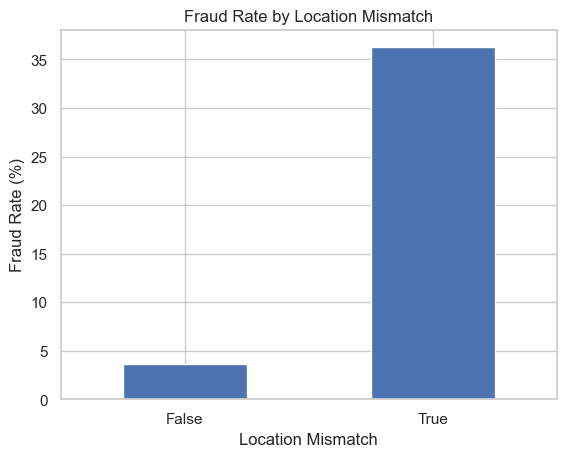

In [76]:
# Plotting Bivariate EDA to show relationship between location mismatch and target variable
fraud_rate = df.groupby('location_mismatch')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('Location Mismatch')
plt.title('Fraud Rate by Location Mismatch')
plt.xticks(rotation=0)
plt.show()

We can see that fraud rate is definetly higher in locations with true mismatch.

In [77]:
# listing all the categorical columns in the dataset

cat_cols=df.select_dtypes(include = ['object', 'category']).columns
cat_cols

Index(['transaction_id', 'customer_id', 'home_country', 'source_currency',
       'dest_currency', 'channel', 'device_id', 'ip_address', 'ip_country',
       'kyc_tier'],
      dtype='object')

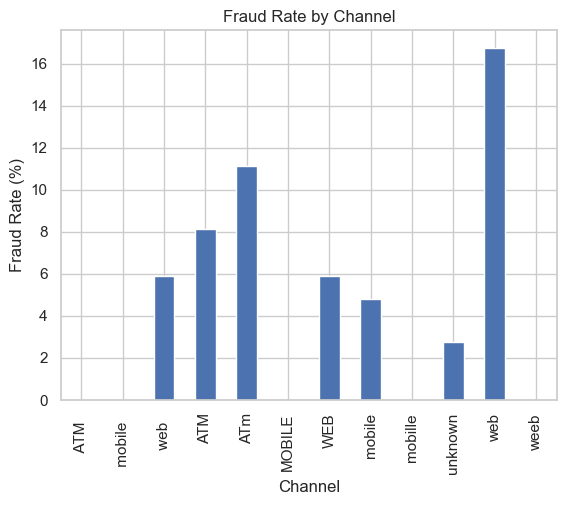

In [79]:
# Plotting Bivariate EDA to show relationship between channel and target variable
fraud_rate = df.groupby('channel')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('Channel')
plt.title('Fraud Rate by Channel')
plt.xticks(rotation=90)
plt.show()

In [80]:
# Checking unique values of the channel feature 
df['channel'].unique()

array(['ATM', 'web', 'mobile', 'WEB', ' web  ', 'MOBILE', 'unknown',
       'mobille', ' mobile  ', 'weeb', 'ATm', ' ATM  '], dtype=object)

In [44]:
# Removing white spaces in the channel feature 
df['channel'] = df['channel'].str.lower().str.strip()

In [81]:
# Checking unique values of the channel feature again
df['channel'].unique()

array(['ATM', 'web', 'mobile', 'WEB', ' web  ', 'MOBILE', 'unknown',
       'mobille', ' mobile  ', 'weeb', 'ATm', ' ATM  '], dtype=object)

In [82]:
# Define mapping strategy for the channel feature 
# df['channel'] = df['channel'].str.lower().str.strip()

df['channel'] = df['channel'].replace({
    'mobille': 'mobile',
    'weeb': 'web'
})

df.loc[~df['channel'].isin(['atm', 'web', 'mobile', 'unknown']), 'channel'] = 'unknown'

In [83]:
# Checking unique values of the channel feature again
df['channel'].unique()

array(['unknown', 'web', 'mobile'], dtype=object)

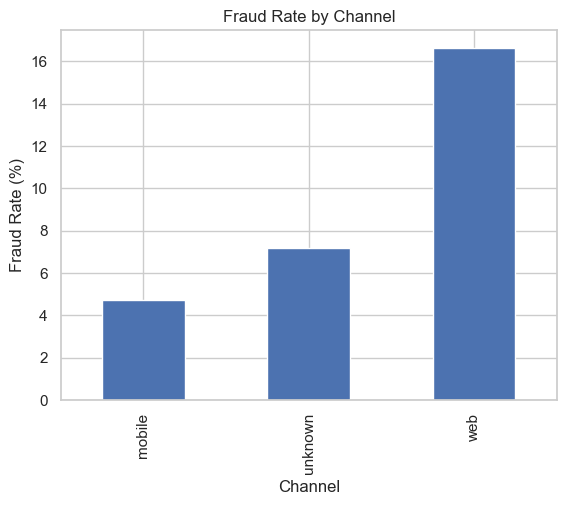

In [84]:
# Plotting Bivariate EDA to show relationship between channel and target variable
fraud_rate = df.groupby('channel')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('Channel')
plt.title('Fraud Rate by Channel')
plt.xticks(rotation=90)
plt.show()

Now, we can see from the cleaned and mapped plot that the channel with the highest fraud rate is web while the least is unknown

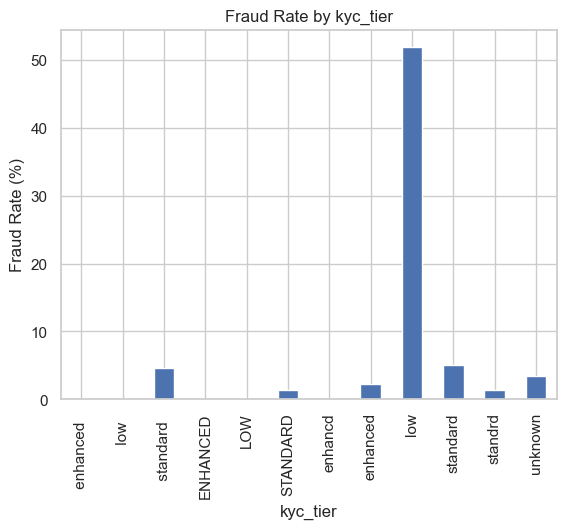

In [85]:
# Plotting Bivariate EDA to show relationship between kyc_tier and target variable
fraud_rate = df.groupby('kyc_tier')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('kyc_tier')
plt.title('Fraud Rate by kyc_tier')
plt.xticks(rotation=90)
plt.show()

In [86]:
# Checking unique values of the kyc_tier feature 
df['kyc_tier'].unique()

array(['standard', 'enhanced', 'low', ' standard  ', 'standrd',
       ' enhanced  ', 'STANDARD', 'unknown', 'enhancd', ' low  ',
       'ENHANCED', 'LOW'], dtype=object)

In [87]:
# Removing white spaces in the kyc_tier feature 
df['kyc_tier'] = df['kyc_tier'].str.lower().str.strip()

In [88]:
# Checking unique values of the kyc_tier feature again
df['kyc_tier'].unique()

array(['standard', 'enhanced', 'low', 'standrd', 'unknown', 'enhancd'],
      dtype=object)

In [89]:
# Define mapping strategy for the kyc_tier feature 

df['kyc_tier'] = df['kyc_tier'].replace({
    'standrd': 'standard',
    'enhancd': 'enhanced'
})

df.loc[~df['kyc_tier'].isin(['standard', 'enhanced', 'low', 'unknown']), 'kyc_tier'] = 'unknown'

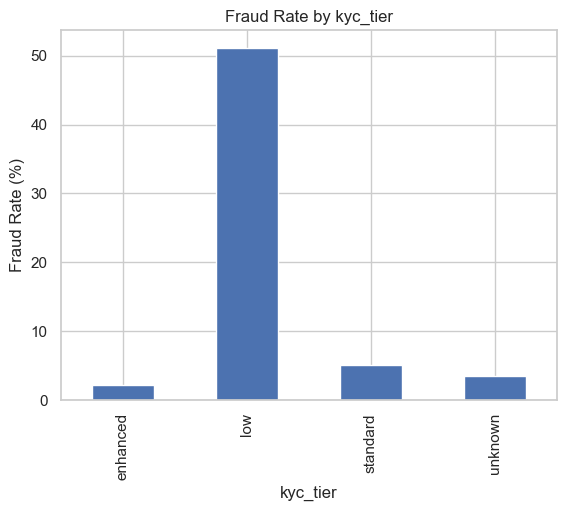

In [90]:
# Plotting Bivariate EDA to show relationship between kyc_tier and target variable
fraud_rate = df.groupby('kyc_tier')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('kyc_tier')
plt.title('Fraud Rate by kyc_tier')
plt.xticks(rotation=90)
plt.show()

From the Kyc_tier vs Target feature EDA, we can see that the most fradulent Kyc_tier is low while the least is enhanced.

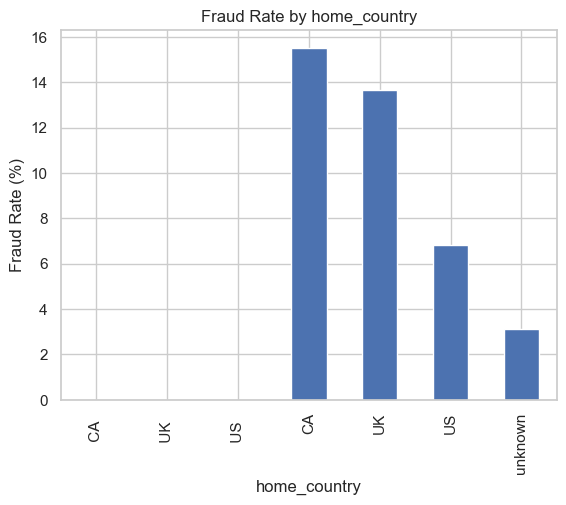

In [91]:
# Plotting Bivariate EDA to show relationship between home_country and target variable
fraud_rate = df.groupby('home_country')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('home_country')
plt.title('Fraud Rate by home_country')
plt.xticks(rotation=90)
plt.show()

In [92]:
# Checking unique values of the home_country feature 
df['home_country'].unique()

array(['US', 'CA', 'UK', ' UK  ', ' US  ', 'unknown', ' CA  '],
      dtype=object)

In [93]:
# Removing while spaces in the home_country feature 
df['home_country'] = df['home_country'].str.lower().str.strip()

In [94]:
# Checking unique values of the home_country feature again
df['home_country'].unique()

array(['us', 'ca', 'uk', 'unknown'], dtype=object)

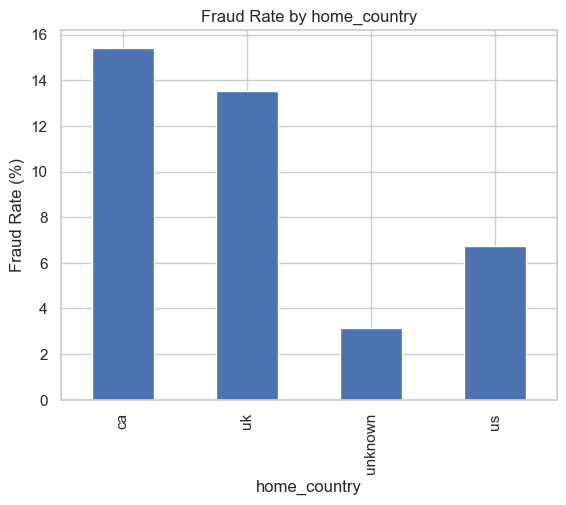

In [95]:
# Plotting Bivariate EDA to show relationship between home_country and target variable again
fraud_rate = df.groupby('home_country')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('home_country')
plt.title('Fraud Rate by home_country')
plt.xticks(rotation=90)
plt.show()